# Лабораторная работа 3. Элементарный перцептрон

9. Реализуйте программно алгоритм обучения элементарного перцептрона для распознавания растровых изображений. Можете использовать следующие варианты реализации:
a)  10 элементарных перцептронов, классифицирующих цифры
как цифры двух классов: эта цифра/другая цифра;
б) один перцептрон, вместо ступенчатой функции использующий
в качестве функции активации функцию мягкого максимума,
обучаемый с помощью стохастического градиентного спуска.Может быть использована обучающая выборка для заданий 3 и 4
главы 3.6 «Задания» раздела «Метод ближайшего соседа».

10. Сформируйте ансамбль из обученных элементарных перцептронов
из предыдущего задания. Сравните для одной и той же выборки результаты классификации растровых изображений с результатами,
получеными методом ближайшего соседа и с помощью отдельного
классификатора из предыдущего задания.


Обучим десять бинарных перцептронов цифра/другая цифра и объединим их в ансамбль. Для сравнения обучим отдельный softmax-классификатор и применим kNN из первой лабы.

## 1. Данные и разбиение

Берём полутоновые изображения цифр из `load_digits`. Каждый растр $8\times8$ превращаем в вектор из 64 пикселей со значениями от 0 до 1. Как в первой лабе, для каждой цифры берём 60 изображений в обучение и 40 в тест. Все три метода получают одни и те же изображения без добавленного шума.

Обучение: 600, тест: 400, признаков: 64


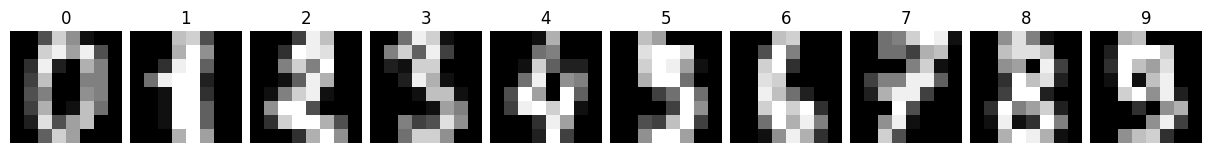

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from sklearn.datasets import load_digits

SEED = 67
CLASSES = np.arange(10)

digits = load_digits()
X, y = digits.data / 16, digits.target
rng = np.random.default_rng(SEED)

train_idx, test_idx = [], []
for digit in CLASSES:
    indices = rng.permutation(np.flatnonzero(y == digit))
    train_idx.extend(indices[:60])
    test_idx.extend(indices[60:100])

X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]
print(f'Обучение: {len(X_train)}, тест: {len(X_test)}, признаков: {X.shape[1]}')

fig, axes = plt.subplots(1, len(CLASSES), figsize=(12, 2.8), layout='constrained')
for ax, digit in zip(axes, CLASSES):
    i = np.flatnonzero(y == digit)[0]
    ax.imshow(X[i].reshape(8, 8), cmap='gray', vmin=0, vmax=1)
    ax.set_title(str(digit))
    ax.axis('off')
plt.show()


## 2. Бинарный перцептрон и ансамбль

Для каждой цифры ставим целевую метку $1$ для её изображений и $-1$ для остальных. Перцептрон считает отклик $s=w^Tx+b$ и выдаёт $1$ при $s\geq0$, иначе $-1$. При ошибке обновляем $w\leftarrow w+yx$ и $b\leftarrow b+y$, где $y$ — целевая метка. Обучение ограничено числом эпох, поскольку выборка может быть линейно неразделима.

Ансамбль выбирает цифру с наибольшим откликом. Так получается одна метка даже при нескольких положительных ответах или при их отсутствии.

In [2]:
def train_perceptron(X, targets, rng, epochs=30):
    weights = np.zeros(X.shape[1])
    bias = 0.0

    for _ in range(epochs):
        mistakes = 0
        for i in rng.permutation(len(X)):
            score = X[i] @ weights + bias
            prediction = 1 if score >= 0 else -1
            if prediction != targets[i]:
                weights += targets[i] * X[i]
                bias += targets[i]
                mistakes += 1

        if mistakes == 0:
            break

    return weights, bias


def train_ensemble(X, labels, epochs=30):
    rng = np.random.default_rng(SEED)
    weights, biases = [], []
    for digit in CLASSES:
        targets = np.where(labels == digit, 1, -1)
        w, b = train_perceptron(X, targets, rng, epochs)
        weights.append(w)
        biases.append(b)

    return np.array(weights), np.array(biases)


def predict_linear(X, weights, biases):
    scores = X @ weights.T + biases
    return CLASSES[scores.argmax(axis=1)]


ensemble_weights, ensemble_biases = train_ensemble(X_train, y_train)

## 3. Один softmax-классификатор

Модель считает десять линейных откликов и преобразует их в вероятности через softmax. Обучаем её стохастическим градиентным спуском по кросс-энтропии. Для одного изображения градиент по откликам равен $p-e_y$, где $e_y$ содержит единицу на позиции верного класса. Параметры обновляются после каждого изображения.

In [3]:
def softmax(scores):
    exponentials = np.exp(scores - scores.max())
    return exponentials / exponentials.sum()


def train_softmax(X, labels, epochs=40, learning_rate=0.05):
    rng = np.random.default_rng(SEED)
    weights = np.zeros((len(CLASSES), X.shape[1]))
    biases = np.zeros(len(CLASSES))

    for _ in range(epochs):
        for i in rng.permutation(len(X)):
            scores = weights @ X[i] + biases
            error = softmax(scores)
            error[labels[i]] -= 1  # Вычитаем единицу для верного класса.

            weights -= learning_rate * np.outer(error, X[i])
            biases -= learning_rate * error

    return weights, biases


softmax_weights, softmax_biases = train_softmax(X_train, y_train)

## 4. Метод ближайших соседей

Используем голосование $k=3$ ближайших обучающих примеров.

In [4]:
def predict_knn(X, X_train, y_train, k=3):
    predictions = []
    for image in X:
        distances = np.sum((X_train - image)**2, axis=1)
        neighbors = np.argsort(distances, kind='stable')[:k]
        votes = np.bincount(y_train[neighbors], minlength=len(CLASSES))
        predictions.append(votes.argmax())

    return np.array(predictions)

## 5. Сравнение на общем тесте

Считаем долю верных ответов и число ошибок. В матрицах ошибок строки обозначают истинные цифры, столбцы — предсказанные. Параметры обучения и $k$ заданы до оценки на тесте.

| Метод | Точность | Ошибок |
|---|---:|---:|
| Ансамбль перцептронов | 93.50% | 26 из 400 |
| Softmax | 94.75% | 21 из 400 |
| kNN (k=3) | 96.75% | 13 из 400 |

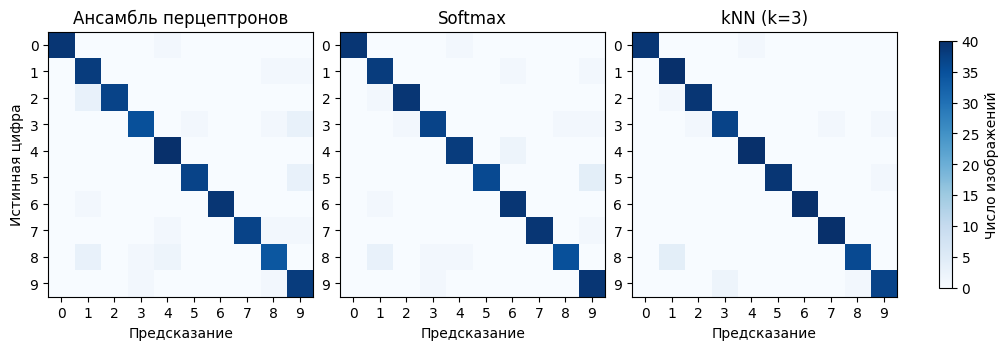

In [5]:
predictions = {
    'Ансамбль перцептронов': predict_linear(X_test, ensemble_weights, ensemble_biases),
    'Softmax': predict_linear(X_test, softmax_weights, softmax_biases),
    'kNN (k=3)': predict_knn(X_test, X_train, y_train),
}

table = ['| Метод | Точность | Ошибок |', '|---|---:|---:|']
for name, predicted in predictions.items():
    accuracy = np.mean(predicted == y_test)
    mistakes = np.count_nonzero(predicted != y_test)
    table.append(f'| {name} | {accuracy:.2%} | {mistakes} из {len(y_test)} |')
display(Markdown('\n'.join(table)))

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), layout='constrained')
for ax, (name, predicted) in zip(axes, predictions.items()):
    matrix = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
    np.add.at(matrix, (y_test, predicted), 1)
    image = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=40)
    ax.set(title=name, xlabel='Предсказание', xticks=CLASSES, yticks=CLASSES)
axes[0].set_ylabel('Истинная цифра')
fig.colorbar(image, ax=axes, shrink=0.75, label='Число изображений')
plt.show()